# 04 — Hyperparameter tuning (MSE2 criterion 2)

**Fake News & Misinformation Detector** · MSE2 §4 (master doc §12.2).

1. the **GridSearchCV** grids for TF-IDF + NB / LR / LinearSVC (5-fold stratified CV on WELFake *train*, seed 42, scoring macro-F1) — every
   configuration tried, straight from the raw `cv_results_` exports `docs/results/gridsearch_{nb,lr,svm}.csv`;
2. the SVM (and LR / NB) heat-maps `docs/figures/sweep_*_heatmap.png`;
3. the marginal effect of each hyperparameter;
4. the **val-vs-test gap** of the winners (from `make eval-models`);
5. the DistilBERT sweep table (`docs/results/distilbert_sweep.md`, written by the GPU agent's `make train-distilbert`) if it exists.

This notebook only reads saved results (≈ 10 s). Regenerate the inputs with `make tune-baselines` (≈ 2 h CPU) → `make train-baselines` → `make eval-models`.

In [1]:
import json, sys, time
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C
from src.models import baselines as B
from src.eval import eval_models as E
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
T0 = time.time()

## 1. The grids

`B.param_grid(model)` — one dict per TF-IDF combination so that `FoldCachedTfidf` fits each (TF-IDF config, fold) only once and re-uses it
for the three C / alpha values (identical scores to a plain `TfidfVectorizer`, `tests/test_models.py`). Fixed for every candidate:
`min_df=2`, `max_df=0.95`, lower-casing inside the vectoriser, `strip_accents="unicode"`. NB keeps `sublinear_tf=True` fixed (18 configs).

In [2]:
from sklearn.model_selection import ParameterGrid
print({m: len(ParameterGrid(B.param_grid(m))) for m in B.MODEL_NAMES})
print("TF-IDF grid:", B.TFIDF_GRID); print("classifier grids:", B.CLF_GRID)
logs = {m: json.loads((B.TRAIN_LOG_DIR / f"gridsearch_{m}.json").read_text()) for m in B.MODEL_NAMES}
pd.DataFrame({m: {"candidates": l["n_candidates"], "n_train": l["n_train"], "cv": l["cv"], "wall_min": round(l["wall_seconds"] / 60, 1),
                  "best CV macro-F1": round(l["best_cv_f1_macro"], 4), "best params": l["best_params"]} for m, l in logs.items()}).T

{'nb': 18, 'lr': 36, 'svm': 36}
TF-IDF grid: {'ngram_range': [(1, 1), (1, 2)], 'max_features': [50000, 100000, 200000], 'sublinear_tf': [True, False]}
classifier grids: {'nb': {'alpha': [0.1, 0.5, 1.0]}, 'lr': {'C': [0.1, 1.0, 10.0]}, 'svm': {'C': [0.1, 1.0, 10.0]}}


,candidates,n_train,cv,wall_min,best CV macro-F1,best params
nb,18,48639,"StratifiedKFold(5, shuffle, seed 42)",17.8,0.8684,"{'clf__alpha': 0.1, 'tfidf__max_features': 200..."
lr,36,48639,"StratifiedKFold(5, shuffle, seed 42)",45.2,0.9428,"{'clf__C': 10.0, 'tfidf__max_features': 100000..."
svm,36,48639,"StratifiedKFold(5, shuffle, seed 42)",37.8,0.9459,"{'clf__C': 1.0, 'tfidf__max_features': 200000,..."


## 2. Every configuration tried (no cherry-picking)

Sorted by mean CV macro-F1; `best` = `rank_test_score == 1`. `mean_fit_time` is small for all but the first C/alpha of each TF-IDF
configuration because the fitted vectoriser is re-used (see §1).

In [3]:
cols = lambda m: ["param_tfidf__ngram_range", "param_tfidf__max_features", "param_tfidf__sublinear_tf",
                  "param_clf__alpha" if m == "nb" else "param_clf__C", "mean_test_score", "std_test_score", "rank_test_score",
                  "mean_fit_time", "best"]
grids = {m: pd.read_csv(B.gridsearch_csv(m)) for m in B.MODEL_NAMES}
for m, g in grids.items():
    print(f"\n=== {B.MODEL_LABEL[m]} — {len(g)} configurations ===")
    display(g[cols(m)].sort_values("mean_test_score", ascending=False).reset_index(drop=True))


=== TF-IDF + Multinomial NB — 18 configurations ===


,param_tfidf__ngram_range,param_tfidf__max_features,param_tfidf__sublinear_tf,param_clf__alpha,mean_test_score,std_test_score,rank_test_score,mean_fit_time,best
0,"(1, 2)",200000,True,0.1,0.8684,0.0036,1,55.3150,True
1,"(1, 2)",200000,True,0.5,0.8635,0.0029,2,0.3368,False
2,"(1, 2)",100000,True,0.1,0.8634,0.0021,3,43.0221,False
3,"(1, 1)",100000,True,0.1,0.8595,0.0026,4,9.3246,False
4,"(1, 1)",200000,True,0.1,0.8595,0.0026,4,11.0603,False
5,"(1, 2)",100000,True,0.5,0.8591,0.0023,6,0.1366,False
6,"(1, 2)",200000,True,1.0,0.8591,0.0031,7,0.3393,False
7,"(1, 2)",50000,True,0.1,0.8576,0.0020,8,47.7123,False
8,"(1, 2)",100000,True,1.0,0.8569,0.0024,9,0.1449,False
9,"(1, 1)",50000,True,0.1,0.8564,0.0021,10,13.9277,False



=== TF-IDF + Logistic Regression — 36 configurations ===


,param_tfidf__ngram_range,param_tfidf__max_features,param_tfidf__sublinear_tf,param_clf__C,mean_test_score,std_test_score,rank_test_score,mean_fit_time,best
0,"(1, 2)",100000,True,10.0,0.9428,0.0026,1,6.1155,True
1,"(1, 2)",200000,True,10.0,0.9428,0.0023,2,6.7434,False
2,"(1, 2)",50000,True,10.0,0.9413,0.0022,3,4.8661,False
3,"(1, 2)",200000,False,10.0,0.9378,0.0020,4,7.2954,False
4,"(1, 2)",100000,False,10.0,0.9369,0.0016,5,7.4841,False
5,"(1, 2)",50000,False,10.0,0.9361,0.0018,6,6.2710,False
6,"(1, 1)",100000,True,10.0,0.9338,0.0021,7,3.7424,False
7,"(1, 1)",200000,True,10.0,0.9338,0.0021,7,3.8642,False
8,"(1, 1)",50000,True,10.0,0.9335,0.0023,9,5.7256,False
9,"(1, 2)",50000,True,1.0,0.9301,0.0027,10,3.4444,False



=== TF-IDF + LinearSVC — 36 configurations ===


,param_tfidf__ngram_range,param_tfidf__max_features,param_tfidf__sublinear_tf,param_clf__C,mean_test_score,std_test_score,rank_test_score,mean_fit_time,best
0,"(1, 2)",200000,True,1.0,0.9459,0.0020,1,2.2128,True
1,"(1, 2)",200000,True,10.0,0.9457,0.0022,2,8.0567,False
2,"(1, 2)",100000,True,1.0,0.9445,0.0024,3,2.7459,False
3,"(1, 2)",100000,True,10.0,0.9428,0.0017,4,7.5222,False
4,"(1, 2)",50000,True,1.0,0.9424,0.0023,5,1.7516,False
5,"(1, 2)",200000,False,1.0,0.9401,0.0023,6,2.2196,False
6,"(1, 2)",100000,False,1.0,0.9387,0.0018,7,1.9773,False
7,"(1, 2)",200000,False,10.0,0.9383,0.0023,8,7.9187,False
8,"(1, 2)",50000,True,10.0,0.9383,0.0023,9,5.8674,False
9,"(1, 2)",50000,False,1.0,0.9370,0.0016,10,1.6885,False


## 3. Heat-maps (regenerated from the CSVs; `make eval-models` writes the same files)

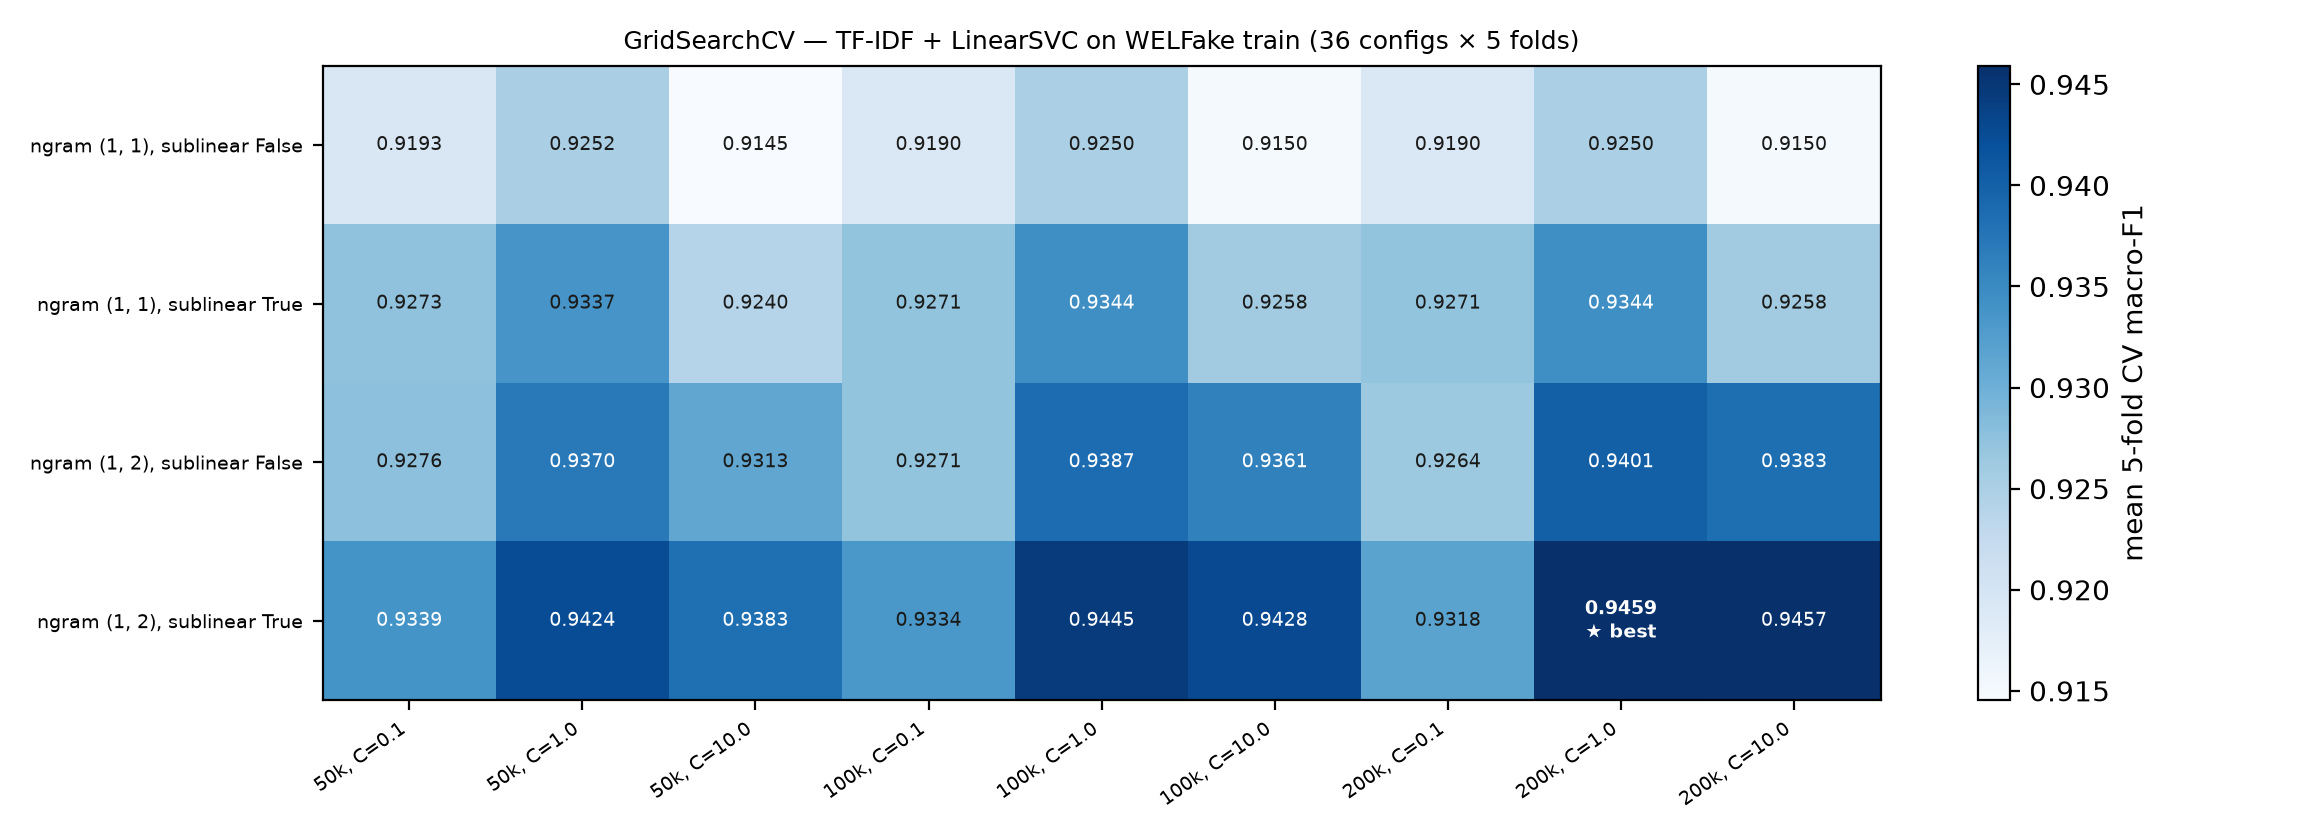

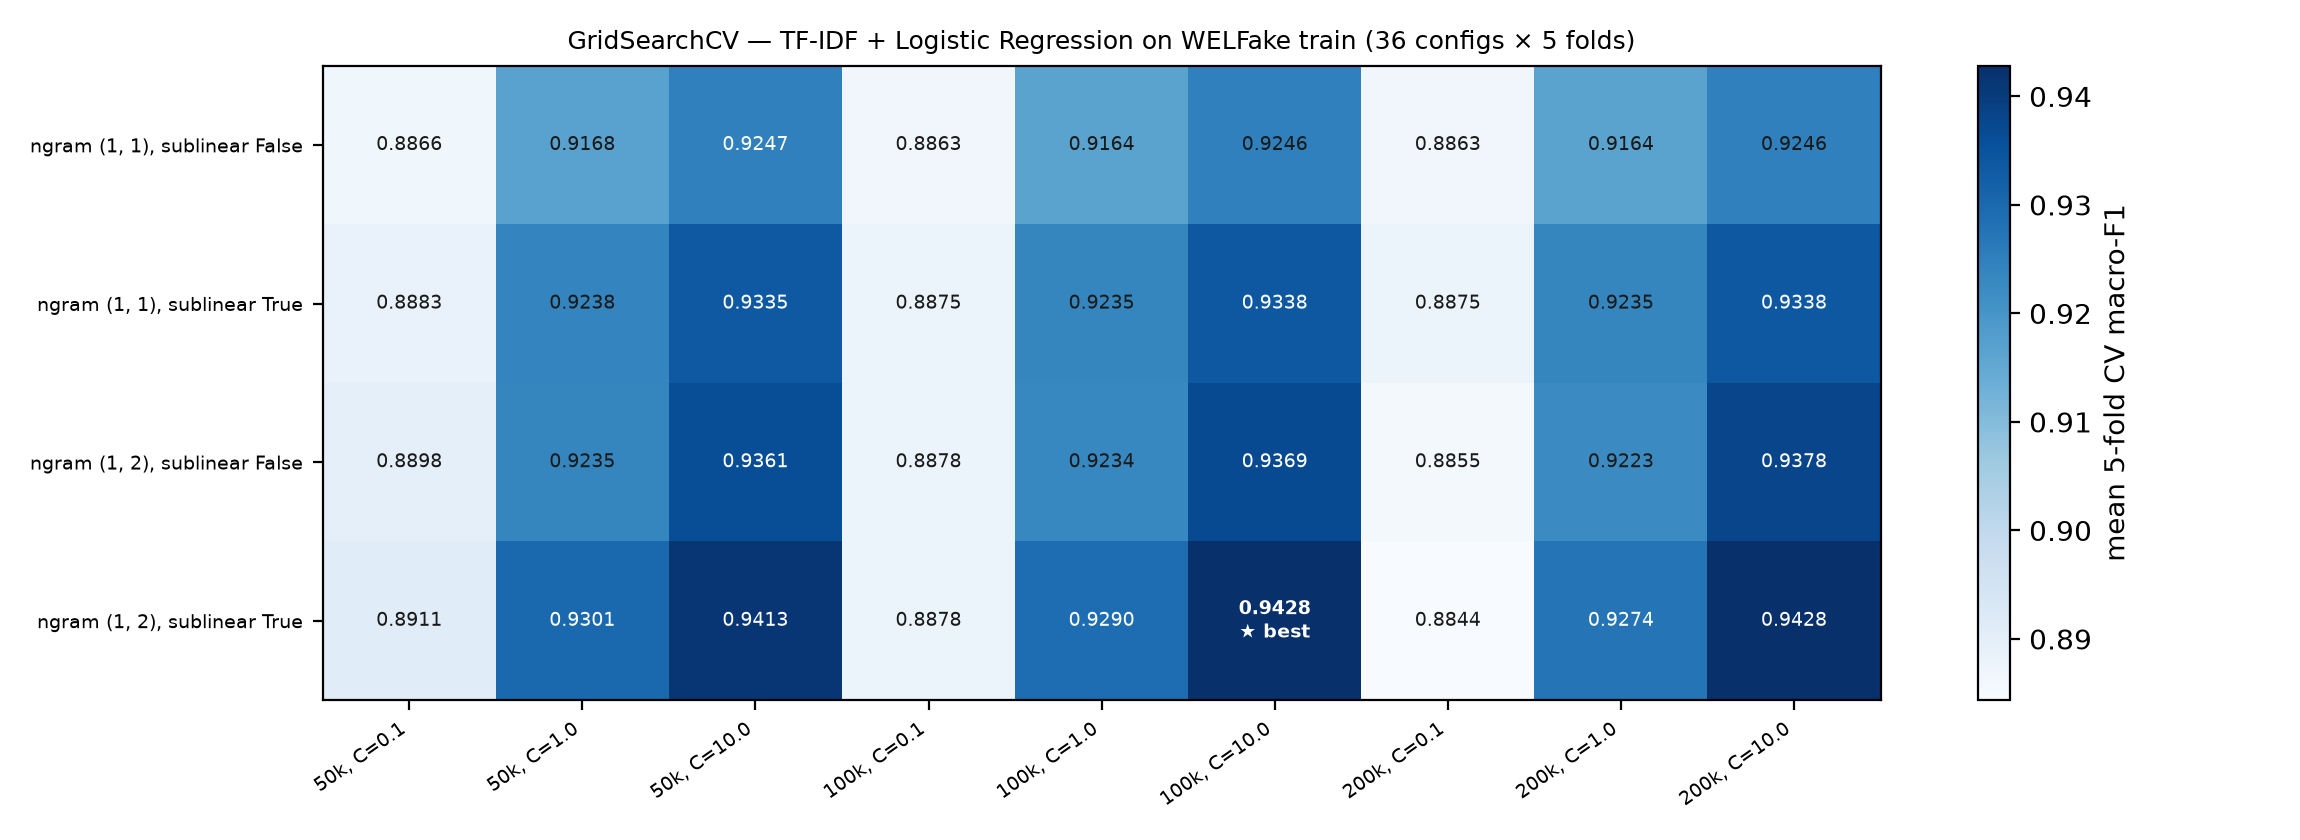

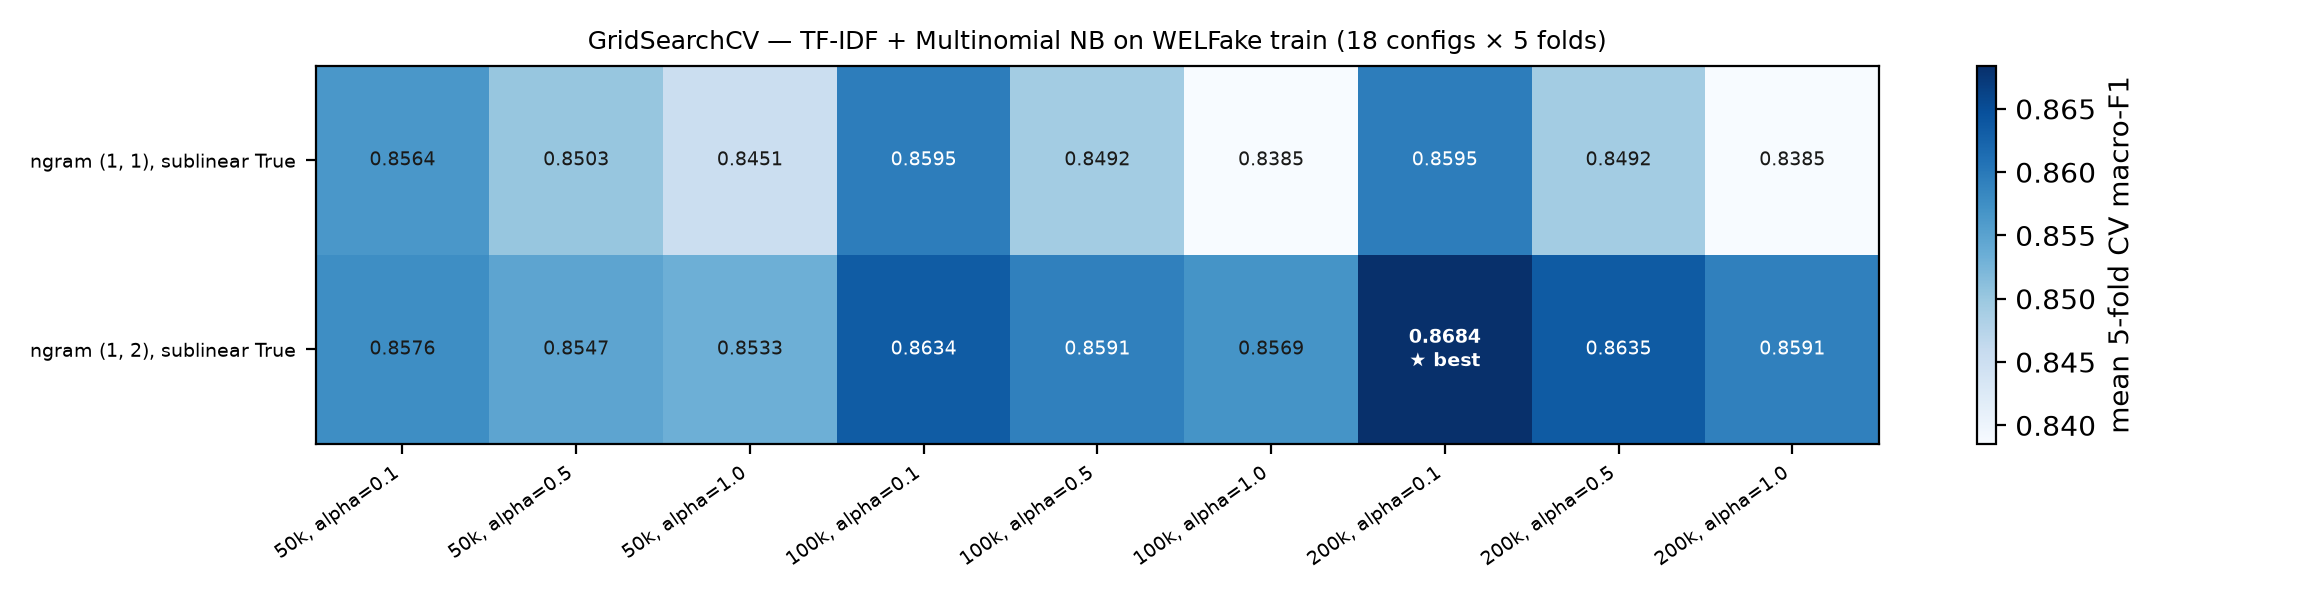

In [4]:
for m in ["svm", "lr", "nb"]:
    E.plot_sweep_heatmap(m)
    display(Image(str(C.FIGURES_DIR / f"sweep_{m}_heatmap.png"), width=900))

## 4. Marginal effect of each hyperparameter

Mean CV macro-F1 over all other settings, per value — a quick read of which knob matters.

In [5]:
rows = []
for m, g in grids.items():
    for p in [c for c in g.columns if c.startswith("param_")]:
        for v, s in g.groupby(p)["mean_test_score"].mean().items():
            rows.append({"model": m, "hyperparameter": p.replace("param_", ""), "value": v, "mean CV macro-F1": s})
marg = pd.DataFrame(rows)
marg.pivot_table(index=["model", "hyperparameter", "value"], values="mean CV macro-F1")

mean CV macro-F1
model hyperparameter      value                   
lr    clf__C              0.1               0.8874
                          1.0               0.9230
                          10.0              0.9344
      tfidf__max_features 50000             0.9155
                          100000            0.9150
                          200000            0.9144
      tfidf__ngram_range  (1, 1)            0.9121
                          (1, 2)            0.9178
      tfidf__sublinear_tf False             0.9126
                          1.0               0.9173
nb    clf__alpha          0.1               0.8608
                          0.5               0.8543
                          1.0               0.8486
      tfidf__max_features 50000             0.8529
                          100000            0.8544
                          200000            0.8564
      tfidf__ngram_range  (1, 1)            0.8496
                          (1, 2)            0.8595
      tfidf__sublinear_tf 1.0               0.8546
svm   clf__C              0.1               0.9266
                          1.0               0.9355
                          10.0              0.9294
      tfidf__max_features 50000             0.9295
                          100000            0.9307
                          200000            0.9312
      tfidf__ngram_range  (1, 1)            0.9243
                          (1, 2)            0.9367
      tfidf__sublinear_tf False             0.9267
                          1.0               0.9344

## 5. Winners: CV vs val vs test (over-fitting check)

CV = mean 5-fold score on train (selection); val / test = the winner refitted on the full train split (`make train-baselines`) and scored by
`make eval-models`. A small, consistent gap means the selection did not over-fit; the test split was used once, for this table.

In [6]:
gap = []
for m in B.MODEL_NAMES + ["distilbert"]:
    p = B.TRAIN_LOG_DIR / f"eval_welfake_{m}.json"
    if not p.exists():
        continue
    r = json.loads(p.read_text())
    gap.append({"model": m, "CV macro-F1": logs[m]["best_cv_f1_macro"] if m in logs else None,
                "val macro-F1": r.get("val", {}).get("f1_macro"), "test macro-F1": r["test"]["f1_macro"],
                "test ROC-AUC": r["test"]["roc_auc"], "val − test": (r.get("val", {}).get("f1_macro") or float("nan")) - r["test"]["f1_macro"]})
pd.DataFrame(gap)

,model,CV macro-F1,val macro-F1,test macro-F1,test ROC-AUC,val − test
0,nb,0.8684,0.8728,0.8758,0.9443,-0.0030
1,lr,0.9428,0.9455,0.9453,0.9875,0.0002
2,svm,0.9459,0.9495,0.9481,0.9884,0.0014


## 6. DistilBERT sweep (lr × max_len, 20k subset) — written by `make train-distilbert`

In [7]:
p = C.RESULTS_DIR / "distilbert_sweep.md"
display(Markdown(p.read_text()) if p.exists() else Markdown("_`docs/results/distilbert_sweep.md` not generated yet (`make train-distilbert`)._"))
print(f"notebook runtime: {time.time() - T0:.0f} s")

# DistilBERT sweep — WELFake (generated by `python -m src.models.distilbert --render`)

`distilbert-base-uncased`, input = title [SEP] text (head truncation), AdamW + linear schedule, warmup ratio 0.1, weight decay 0.01, fp16, 3 epochs with the best epoch (val macro-F1) kept, seed 42. Sweep = 20,000-row stratified subset of WELFake train, evaluated on the full WELFake val split (6,080). Selection metric: val macro-F1. Per-run logs: `docs/results/train_logs/distilbert_sweep_*.json`.

| run | lr | max_len | batch × accum | best epoch / 3 | warmup | seed | val macro-F1 (best ep.) | val acc | per-epoch val macro-F1 | minutes | peak GPU GiB | hardware |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| sweep 20k (20000) | 2e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9869** | 0.9872 | 0.9792 → 0.9807 → 0.9869 | 14.8 | 1.68 | NVIDIA GeForce RTX 2050 |
| sweep 20k (20000) | 3e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9863** | 0.9865 | 0.9826 → 0.9854 → 0.9863 | 14.3 | 1.68 | NVIDIA GeForce RTX 2050 |
| **best completed** sweep 20k (20000) | 5e-05 | 256 | 16 × 1 | 3 | 0.1 | 42 | **0.9871** | 0.9873 | 0.9792 → 0.9870 → 0.9871 | 15.2 | 1.69 | NVIDIA GeForce RTX 2050 |
| sweep 20k | 2e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| sweep 20k | 3e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| sweep 20k | 5e-05 | 512 | 8 × 2 | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |
| full-train retrain of the winner (48,639) | — | — | — | not run (stopped on user decision, 2026-10-26) — deferred to ESE |  |  |  |  |  |  |  |  |

**Best completed run:** lr = 5e-05, max_len = 256 (val macro-F1 0.9871 at epoch 3). Only 3 of 6 configs ran, so this is the best of the completed runs, not a sweep winner; the sweep runs save no weights, so **no DistilBERT checkpoint exists** and no DistilBERT test number exists (`data/models/distilbert-welfake-v1/` was not created; the served classifier stays TF-IDF). MSE2 objective O1 (DistilBERT macro-F1 ≥ 0.95 on WELFake test) is therefore not checked.

**lr = 5e-5:** at max_len 256 it fits the 20k subset fastest (train loss 0.0077 at epoch 3 vs 0.0153 / 0.0105 for 2e-5 / 3e-5) and its val loss rises from epoch 2 (0.0572) to epoch 3 (0.0671), i.e. it starts to overfit, while val macro-F1 stays flat (0.9870 -> 0.9871); it ties lr 2e-5 (0.9869) within 0.0002 — no lr is clearly better at 256.



notebook runtime: 1 s


**Reading** (marginal means from §4, `gridsearch_*.csv`, 26 Oct 2026). **Bigrams beat unigrams for every model** (SVM 0.9367 vs 0.9243,
LR 0.9178 vs 0.9121, NB 0.8595 vs 0.8496) and `sublinear_tf=True` helps LR/SVM (SVM 0.9344 vs 0.9267). **Vocabulary size matters least**
(≤ 0.002 between 50k and 200k); the unigram rows are identical at 100k and 200k because the unigram vocabulary after `min_df=2` is smaller than
100k. **Regularisation is the big knob for LR** (C 0.1 → 10: 0.887 → 0.934 mean) — the winner C = 10 sits at the edge of the grid, so a
larger C is worth one extra check at ESE; LinearSVC peaks at C = 1. NB prefers the smallest alpha (0.1) and stays the weakest model everywhere.
Winners: SVM (1,2)-grams / 200k / sublinear / C = 1 (CV 0.9459), LR (1,2) / 100k / sublinear / C = 10 (CV 0.9428), NB (1,2) / 200k / alpha 0.1
(CV 0.8684). Their val-vs-test gaps (§5) are within ±0.003 on WELFake, so CV selection did not over-fit.